In [1]:
import pandas as pd
from pathlib import Path

# Load the graph-enhanced transaction dataset
DATA_PATH = Path("../data/transactions_graph.parquet")

df = pd.read_parquet(DATA_PATH)

# Inspect the loaded dataset
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5078345, 20)


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,sender,receiver,sender_previous_tx_count,sender_previous_out_degree,receiver_previous_in_degree,receiver_previous_tx_count,sender_previous_in_degree,receiver_previous_out_degree,previous_pair_tx_count
0,2022-09-01,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0,3209_8000F4670,3209_8000F4670,0,0,0,0,0,0,0
1,2022-09-01,1420,8005DFEB0,1420,8005DFEB0,897.37,US Dollar,897.37,US Dollar,Reinvestment,0,1420_8005DFEB0,1420_8005DFEB0,0,0,0,0,0,0,0
2,2022-09-01,10,8000F6850,10,8000F6850,99986.94,US Dollar,99986.94,US Dollar,Reinvestment,0,10_8000F6850,10_8000F6850,0,0,0,0,0,0,0
3,2022-09-01,12,8001167D0,12,8001167D0,16.08,US Dollar,16.08,US Dollar,Reinvestment,0,12_8001167D0,12_8001167D0,0,0,0,0,0,0,0
4,2022-09-01,1,8001364A0,1,8001364A0,10.30,US Dollar,10.30,US Dollar,Reinvestment,0,1_8001364A0,1_8001364A0,0,0,0,0,0,0,0


In [2]:
# Define the historical graph features
graph_features = [
    "sender_previous_tx_count",
    "sender_previous_in_degree",
    "sender_previous_out_degree",
    "receiver_previous_tx_count",
    "receiver_previous_in_degree",
    "receiver_previous_out_degree",
    "previous_pair_tx_count"
]

# Validate dataset integrity
assert df.shape == (5_078_345, 20)
assert all(col in df.columns for col in graph_features)
assert df[graph_features].notna().all().all()
assert (df[graph_features] >= 0).all().all()
assert df["Timestamp"].is_monotonic_increasing
assert df["Is Laundering"].sum() == 5177

# Inspect graph feature statistics
display(df[graph_features].describe().T)

print("Dataset validation: PASSED")
print("Graph features:", len(graph_features))
print("Total transactions:", len(df))

,count,mean,std,min,25%,50%,75%,max
sender_previous_tx_count,5078345.0,4127.530693,19298.107259,0.0,4.0,16.0,41.0,168665.0
sender_previous_in_degree,5078345.0,22.969739,93.589994,0.0,1.0,2.0,3.0,545.0
sender_previous_out_degree,5078345.0,629.609176,2605.274106,0.0,2.0,3.0,6.0,14230.0
receiver_previous_tx_count,5078345.0,12.938378,14.828362,0.0,4.0,11.0,19.0,1083.0
receiver_previous_in_degree,5078345.0,2.910289,7.656543,0.0,2.0,3.0,3.0,545.0
receiver_previous_out_degree,5078345.0,6.049667,217.764205,0.0,1.0,1.0,2.0,14230.0
previous_pair_tx_count,5078345.0,7.444157,7.816555,0.0,1.0,5.0,12.0,88.0


Dataset validation: PASSED
Graph features: 7
Total transactions: 5078345


In [3]:
import numpy as np

# Standardize account column names
df = df.rename(columns={
    "Account": "From Account",
    "Account.1": "To Account"
})

# Extract temporal features
df["Hour"] = df["Timestamp"].dt.hour
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek

# Apply logarithmic transformation to transaction amounts
df["Log Amount Paid"] = np.log1p(
    df["Amount Paid"].clip(lower=0)
)

df["Log Amount Received"] = np.log1p(
    df["Amount Received"].clip(lower=0)
)

# Reproduce the additional baseline transaction features
df["Amounts Equal"] = np.isclose(
    df["Amount Paid"], df["Amount Received"]
).astype("uint8")

df["Same Currency"] = (
    df["Payment Currency"] == df["Receiving Currency"]
).astype("uint8")

df["Same Bank"] = (
    df["From Bank"] == df["To Bank"]
).astype("uint8")

df["Same Account"] = (
    (df["From Bank"] == df["To Bank"])
    & (df["From Account"] == df["To Account"])
).astype("uint8")

print("Dataset shape:", df.shape)
display(df.iloc[:, -8:].head())

Dataset shape: (5078345, 28)


,Hour,DayOfWeek,Log Amount Paid,Log Amount Received,Amounts Equal,Same Currency,Same Bank,Same Account
0,0,3,9.594008,9.594008,1,1,1,1
1,0,3,6.800582,6.800582,1,1,1,1
2,0,3,11.512805,11.512805,1,1,1,1
3,0,3,2.837908,2.837908,1,1,1,1
4,0,3,2.424803,2.424803,1,1,1,1


In [4]:
# Select the original numerical transaction features
numeric_features = [
    "Amount Paid",
    "Amount Received",
    "Log Amount Paid",
    "Log Amount Received",
    "Hour",
    "DayOfWeek",
    "Amounts Equal",
    "Same Currency",
    "Same Bank",
    "Same Account"
]

# Select the categorical transaction features
categorical_features = [
    "Payment Currency",
    "Receiving Currency",
    "Payment Format"
]

# Combine transaction and graph features
selected_features = (
    numeric_features
    + categorical_features
    + graph_features
)

# Define the target variable
target = "Is Laundering"

# Validate the selected features
assert all(col in df.columns for col in selected_features)
assert len(selected_features) == len(set(selected_features))
assert target not in selected_features

print("Numerical transaction features:", len(numeric_features))
print("Categorical transaction features:", len(categorical_features))
print("Graph features:", len(graph_features))
print("Total selected features:", len(selected_features))
print("Target:", target)

display(df[selected_features + [target]].head())

Numerical transaction features: 10
Categorical transaction features: 3
Graph features: 7
Total selected features: 20
Target: Is Laundering


,Amount Paid,Amount Received,Log Amount Paid,Log Amount Received,Hour,DayOfWeek,Amounts Equal,Same Currency,Same Bank,Same Account,...,Receiving Currency,Payment Format,sender_previous_tx_count,sender_previous_in_degree,sender_previous_out_degree,receiver_previous_tx_count,receiver_previous_in_degree,receiver_previous_out_degree,previous_pair_tx_count,Is Laundering
0,14675.57,14675.57,9.594008,9.594008,0,3,1,1,1,1,...,US Dollar,Reinvestment,0,0,0,0,0,0,0,0
1,897.37,897.37,6.800582,6.800582,0,3,1,1,1,1,...,US Dollar,Reinvestment,0,0,0,0,0,0,0,0
2,99986.94,99986.94,11.512805,11.512805,0,3,1,1,1,1,...,US Dollar,Reinvestment,0,0,0,0,0,0,0,0
3,16.08,16.08,2.837908,2.837908,0,3,1,1,1,1,...,US Dollar,Reinvestment,0,0,0,0,0,0,0,0
4,10.30,10.30,2.424803,2.424803,0,3,1,1,1,1,...,US Dollar,Reinvestment,0,0,0,0,0,0,0,0


In [5]:
# Define the original baseline split boundaries
train_end = pd.Timestamp("2022-09-06 13:35:00")
val_end = pd.Timestamp("2022-09-08 16:11:00")

# Create chronological data partitions
train_df = df[df["Timestamp"] <= train_end]

val_df = df[
    (df["Timestamp"] > train_end)
    & (df["Timestamp"] <= val_end)
]

test_df = df[df["Timestamp"] > val_end]

# Verify the original baseline partition sizes
assert len(train_df) == 3_046_861
assert len(val_df) == 1_015_602
assert len(test_df) == 1_015_882

# Summarize the data partitions
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{name}:")
    print(f"  Transactions: {len(data):,}")
    print(f"  Laundering: {data[target].sum():,}")
    print(f"  Laundering rate: {data[target].mean():.4%}")
    print(f"  Period: {data['Timestamp'].min()} - "
          f"{data['Timestamp'].max()}")
    print()

Training:
  Transactions: 3,046,861
  Laundering: 2,297
  Laundering rate: 0.0754%
  Period: 2022-09-01 00:00:00 - 2022-09-06 13:35:00

Validation:
  Transactions: 1,015,602
  Laundering: 1,082
  Laundering rate: 0.1065%
  Period: 2022-09-06 13:36:00 - 2022-09-08 16:11:00

Test:
  Transactions: 1,015,882
  Laundering: 1,798
  Laundering rate: 0.1770%
  Period: 2022-09-08 16:12:00 - 2022-09-18 16:18:00



In [6]:
# Encode categorical features
X_train = pd.get_dummies(
    train_df[selected_features],
    columns=categorical_features,
    dtype=np.uint8
)

X_val = pd.get_dummies(
    val_df[selected_features],
    columns=categorical_features,
    dtype=np.uint8
)

X_test = pd.get_dummies(
    test_df[selected_features],
    columns=categorical_features,
    dtype=np.uint8
)

# Align validation and test features with training features
X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Separate the target variable
y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

# Verify feature consistency
assert X_train.shape[1] == 54
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)
assert all(col in X_train.columns for col in graph_features)

# Display the final feature matrix dimensions
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

Training features: (3046861, 54)
Validation features: (1015602, 54)
Test features: (1015882, 54)


In [7]:
from xgboost import XGBClassifier
from time import perf_counter

# Verify the expected feature dimensions
assert X_train.shape == (3_046_861, 54)
assert X_val.shape == (1_015_602, 54)
assert X_train.columns.equals(X_val.columns)
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)

# Reuse the best baseline hyperparameters
graph_model = XGBClassifier(
    n_estimators=2000,
    early_stopping_rounds=50,
    max_depth=7,
    learning_rate=0.05,
    min_child_weight=1,
    reg_lambda=10.0,
    scale_pos_weight=1.0,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

# Train the graph-enhanced model
started = perf_counter()

graph_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=20
)

# Report training results
print("\nGraph XGBoost training completed.")
print("Best number of trees:", graph_model.best_iteration + 1)
print("Best validation AUCPR:", graph_model.best_score)
print("Training time (seconds):", round(perf_counter() - started, 2))

[0]	validation_0-aucpr:0.04454
[20]	validation_0-aucpr:0.33068
[40]	validation_0-aucpr:0.37253
[60]	validation_0-aucpr:0.39767
[80]	validation_0-aucpr:0.40823
[100]	validation_0-aucpr:0.41951
[120]	validation_0-aucpr:0.42381
[140]	validation_0-aucpr:0.42832
[160]	validation_0-aucpr:0.43064
[180]	validation_0-aucpr:0.43502
[200]	validation_0-aucpr:0.43906
[220]	validation_0-aucpr:0.44174
[240]	validation_0-aucpr:0.44314
[260]	validation_0-aucpr:0.44539
[280]	validation_0-aucpr:0.44718
[300]	validation_0-aucpr:0.45006
[320]	validation_0-aucpr:0.45005
[340]	validation_0-aucpr:0.45060
[360]	validation_0-aucpr:0.45069
[380]	validation_0-aucpr:0.45108
[400]	validation_0-aucpr:0.45116
[420]	validation_0-aucpr:0.45120
[440]	validation_0-aucpr:0.45208
[460]	validation_0-aucpr:0.45325
[480]	validation_0-aucpr:0.45340
[500]	validation_0-aucpr:0.45338
[520]	validation_0-aucpr:0.45392
[540]	validation_0-aucpr:0.45270
[560]	validation_0-aucpr:0.45261
[569]	validation_0-aucpr:0.45222

Graph XGBoost t

In [8]:
from sklearn.metrics import average_precision_score

# Predict laundering scores on the validation dataset
graph_val_proba = graph_model.predict_proba(X_val)[:, 1]

# Calculate validation Average Precision
graph_val_ap = average_precision_score(
    y_val, graph_val_proba
)

# Reference performance of the traditional baseline
baseline_val_ap = 0.066664

# Calculate performance improvement
absolute_improvement = graph_val_ap - baseline_val_ap

relative_improvement = (
    graph_val_ap / baseline_val_ap - 1
) * 100

# Display the comparison
print(f"Baseline Validation AP: {baseline_val_ap:.4%}")
print(f"Graph Validation AP: {graph_val_ap:.4%}")

print(
    f"Absolute improvement: "
    f"{absolute_improvement * 100:.2f} percentage points"
)

print(f"Relative improvement: {relative_improvement:.2f}%")
print(f"Performance ratio: {graph_val_ap / baseline_val_ap:.2f}x")

Baseline Validation AP: 6.6664%
Graph Validation AP: 45.4112%
Absolute improvement: 38.74 percentage points
Relative improvement: 581.19%
Performance ratio: 6.81x


In [9]:
# Select normal and laundering transactions from both partitions
verification_sample = pd.concat([
    train_df[train_df[target] == 0].sample(5, random_state=42),
    train_df[train_df[target] == 1].sample(5, random_state=42),
    val_df[val_df[target] == 0].sample(5, random_state=42),
    val_df[val_df[target] == 1].sample(5, random_state=42)
])

# Restrict the verification history to training and validation
history_source = df.loc[
    df["Timestamp"] <= val_end,
    ["Timestamp", "sender", "receiver"]
]

verification_results = []

# Independently recompute historical graph features
for idx, row in verification_sample.iterrows():

    history = history_source[
        history_source["Timestamp"] < row["Timestamp"]
    ]

    sender = row["sender"]
    receiver = row["receiver"]

    sender_out = history[history["sender"] == sender]
    sender_in = history[history["receiver"] == sender]

    receiver_out = history[history["sender"] == receiver]
    receiver_in = history[history["receiver"] == receiver]

    # Calculate expected feature values directly
    expected = {
        "sender_previous_tx_count": len(sender_out),
        "sender_previous_in_degree": sender_in["sender"].nunique(),
        "sender_previous_out_degree": sender_out["receiver"].nunique(),
        "receiver_previous_tx_count": len(receiver_in),
        "receiver_previous_in_degree": receiver_in["sender"].nunique(),
        "receiver_previous_out_degree": receiver_out["receiver"].nunique(),
        "previous_pair_tx_count": (
            sender_out["receiver"] == receiver
        ).sum()
    }

    # Compare recomputed and stored feature values
    for feature, expected_value in expected.items():

        stored_value = row[feature]

        verification_results.append({
            "Transaction Index": idx,
            "Feature": feature,
            "Stored": stored_value,
            "Recomputed": expected_value,
            "Match": stored_value == expected_value
        })

# Summarize verification results
verification_df = pd.DataFrame(verification_results)

display(
    verification_df.groupby("Feature")["Match"]
    .agg(["count", "sum", "mean"])
)

mismatches = verification_df[~verification_df["Match"]]

print("Verified transactions:", len(verification_sample))
print("Total feature checks:", len(verification_df))
print("Matching values:", verification_df["Match"].sum())
print("Mismatches:", len(mismatches))

if mismatches.empty:
    print("Independent verification: PASSED")
else:
    display(mismatches)
    print("Independent verification: FAILED")

,count,sum,mean
Feature,,,
previous_pair_tx_count,20,20,1.0
receiver_previous_in_degree,20,20,1.0
receiver_previous_out_degree,20,20,1.0
receiver_previous_tx_count,20,20,1.0
sender_previous_in_degree,20,20,1.0
sender_previous_out_degree,20,20,1.0
sender_previous_tx_count,20,20,1.0


Verified transactions: 20
Total feature checks: 140
Matching values: 140
Mismatches: 0
Independent verification: PASSED


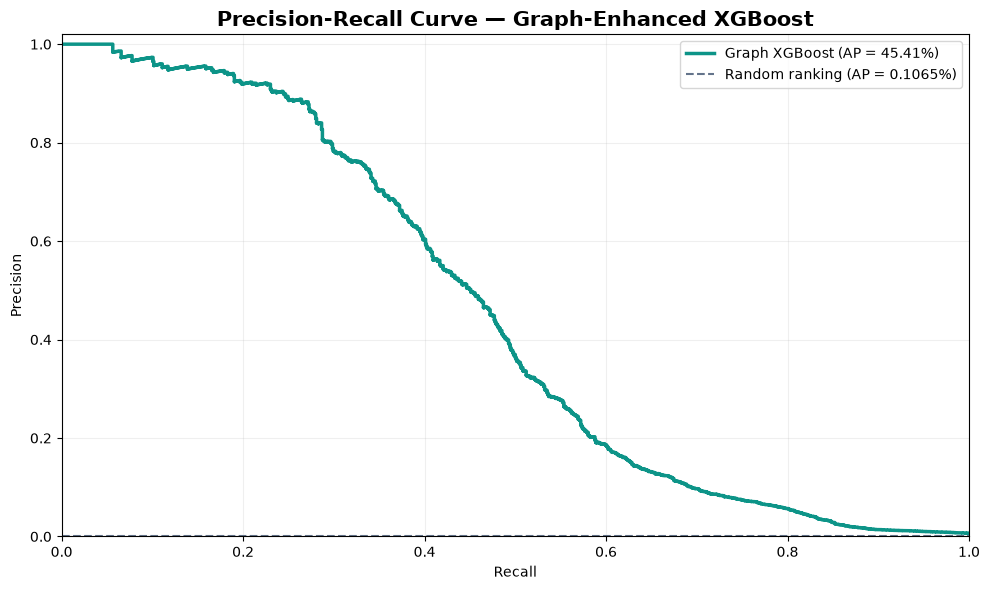

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall across thresholds
graph_precision, graph_recall, graph_thresholds = (
    precision_recall_curve(y_val, graph_val_proba)
)

# Calculate the random-ranking reference
random_ap = y_val.mean()

# Create the precision-recall curve
fig, ax = plt.subplots(figsize=(10, 6))

ax.step(
    graph_recall,
    graph_precision,
    where="post",
    color="#0D9488",
    linewidth=2.5,
    label=f"Graph XGBoost (AP = {graph_val_ap:.2%})"
)

ax.axhline(
    random_ap,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    label=f"Random ranking (AP = {random_ap:.4%})"
)

ax.set_title(
    "Precision-Recall Curve — Graph-Enhanced XGBoost",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(alpha=0.2)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import ParameterSampler

# Define the hyperparameter search space
param_dist = {
    "max_depth": [4, 5, 6, 7, 8, 9],
    "min_child_weight": [1, 3, 5, 10],
    "reg_lambda": [1.0, 5.0, 10.0, 20.0],
    "scale_pos_weight": [1.0, 5.0, 10.0, 20.0]
}

# Generate reproducible hyperparameter configurations
param_list = list(ParameterSampler(
    param_dist,
    n_iter=10,
    random_state=42
))

# Inspect the selected configurations
display(pd.DataFrame(param_list))

print("Number of trials:", len(param_list))

,scale_pos_weight,reg_lambda,min_child_weight,max_depth
0,1.0,20.0,1,8
1,10.0,10.0,10,7
2,20.0,1.0,5,9
3,1.0,20.0,1,9
4,1.0,10.0,10,4
5,1.0,5.0,10,9
6,5.0,1.0,5,4
7,10.0,1.0,10,5
8,20.0,5.0,10,9
9,10.0,20.0,5,7


Number of trials: 10


In [12]:
# Initialize the search with the initial graph model
best_graph_model = graph_model
best_graph_ap = graph_val_ap
best_graph_params = graph_model.get_params()

search_results = []

search_started = perf_counter()

# Train and evaluate each configuration
for trial, params in enumerate(param_list, start=1):

    started = perf_counter()

    model = XGBClassifier(
        n_estimators=2000,
        early_stopping_rounds=50,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
        **params
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    # Evaluate validation Average Precision
    val_proba = model.predict_proba(X_val)[:, 1]
    val_ap = average_precision_score(y_val, val_proba)

    elapsed = perf_counter() - started

    # Store trial results
    search_results.append({
        "Trial": trial,
        **params,
        "Validation AP": val_ap,
        "Best Trees": model.best_iteration + 1,
        "Training Time (s)": elapsed
    })

    # Update the best model if performance improves
    if val_ap > best_graph_ap:
        best_graph_ap = val_ap
        best_graph_model = model
        best_graph_params = model.get_params()

    print(
        f"Trial {trial:02d}/10 | "
        f"AP: {val_ap:.4%} | "
        f"Trees: {model.best_iteration + 1} | "
        f"Time: {elapsed:.1f}s"
    )

# Rank all configurations by validation performance
search_df = pd.DataFrame(search_results)

display(
    search_df.sort_values(
        "Validation AP", ascending=False
    ).reset_index(drop=True)
)

# Report the best performance
print(f"\nInitial Graph AP: {graph_val_ap:.4%}")
print(f"Best Graph AP: {best_graph_ap:.4%}")
print(f"Total search time: "
      f"{(perf_counter() - search_started) / 60:.2f} minutes")

Trial 01/10 | AP: 45.2609% | Trees: 520 | Time: 173.1s
Trial 02/10 | AP: 42.9960% | Trees: 405 | Time: 120.8s
Trial 03/10 | AP: 41.7311% | Trees: 252 | Time: 87.2s
Trial 04/10 | AP: 45.0656% | Trees: 446 | Time: 183.2s
Trial 05/10 | AP: 43.6760% | Trees: 838 | Time: 331.0s
Trial 06/10 | AP: 44.9465% | Trees: 301 | Time: 93.8s
Trial 07/10 | AP: 43.3596% | Trees: 778 | Time: 174.2s
Trial 08/10 | AP: 42.4405% | Trees: 582 | Time: 140.7s
Trial 09/10 | AP: 42.0291% | Trees: 363 | Time: 103.3s
Trial 10/10 | AP: 43.2110% | Trees: 379 | Time: 108.1s


,Trial,scale_pos_weight,reg_lambda,min_child_weight,max_depth,Validation AP,Best Trees,Training Time (s)
0,1,1.0,20.0,1,8,0.452609,520,173.143661
1,4,1.0,20.0,1,9,0.450656,446,183.182860
2,6,1.0,5.0,10,9,0.449465,301,93.819109
3,5,1.0,10.0,10,4,0.436760,838,331.011188
4,7,5.0,1.0,5,4,0.433596,778,174.240399
5,10,10.0,20.0,5,7,0.432110,379,108.093915
6,2,10.0,10.0,10,7,0.429960,405,120.766798
7,8,10.0,1.0,10,5,0.424405,582,140.725506
8,9,20.0,5.0,10,9,0.420291,363,103.289323
9,3,20.0,1.0,5,9,0.417311,252,87.239725



Initial Graph AP: 45.4112%
Best Graph AP: 45.4112%
Total search time: 25.26 minutes


In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Generate validation predictions
best_graph_val_proba = best_graph_model.predict_proba(X_val)[:, 1]

# Calculate precision and recall across thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, best_graph_val_proba
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

# Select the optimal threshold
best_idx = np.argmax(f1_scores)
best_graph_threshold = thresholds[best_idx]

# Compare default and optimized thresholds
threshold_results = []

for name, threshold in [
    ("Default", 0.5),
    ("Optimized", best_graph_threshold)
]:
    predictions = (best_graph_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Strategy": name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Alerts": tp + fp
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(6))

print(f"Optimal threshold: {best_graph_threshold:.6f}")
print(f"Best validation F1-score: {f1_scores[best_idx]:.4%}")

,Strategy,Threshold,Precision,Recall,F1-score,TP,FP,FN,TN,Alerts
0,Default,0.500000,0.886076,0.25878,0.400572,280,36,802,1014484,316
1,Optimized,0.218607,0.625183,0.39464,0.483853,427,256,655,1014264,683


Optimal threshold: 0.218607
Best validation F1-score: 48.3853%


,Feature,Gain,Feature Type
0,Payment Format_ACH,314.4258,Transaction
1,Payment Format_Reinvestment,273.6570,Transaction
2,Same Account,21.0077,Transaction
3,previous_pair_tx_count,19.7447,Graph
4,Payment Currency_Saudi Riyal,11.1145,Transaction
5,Receiving Currency_Saudi Riyal,10.9167,Transaction
6,Amounts Equal,9.2195,Transaction
7,sender_previous_out_degree,8.9039,Graph
8,Same Bank,8.7737,Transaction
9,Receiving Currency_Shekel,7.9606,Transaction


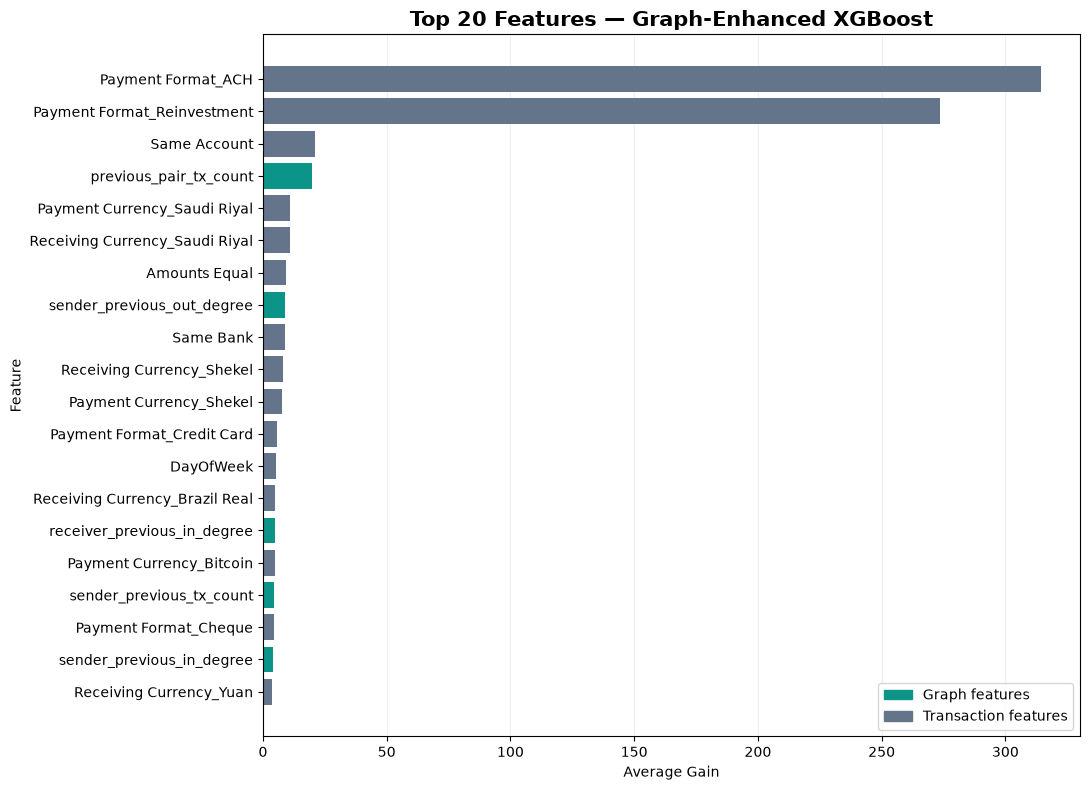

In [14]:
# Extract gain-based feature importance
gain_scores = best_graph_model.get_booster().get_score(
    importance_type="gain"
)

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Gain": [
        gain_scores.get(feature, 0.0)
        for feature in X_train.columns
    ]
})

# Identify feature groups
importance_df["Feature Type"] = np.where(
    importance_df["Feature"].isin(graph_features),
    "Graph",
    "Transaction"
)

# Rank features by importance
importance_df = importance_df.sort_values(
    "Gain", ascending=False
).reset_index(drop=True)

# Display the top 20 features
display(importance_df.head(20).round(4))

# Visualize the top 20 features
top_features = importance_df.head(20).iloc[::-1]

colors = top_features["Feature Type"].map({
    "Graph": "#0D9488",
    "Transaction": "#64748B"
})

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    top_features["Feature"],
    top_features["Gain"],
    color=colors
)

ax.set_title(
    "Top 20 Features — Graph-Enhanced XGBoost",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Average Gain")
ax.set_ylabel("Feature")

from matplotlib.patches import Patch

ax.legend(handles=[
    Patch(color="#0D9488", label="Graph features"),
    Patch(color="#64748B", label="Transaction features")
])

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

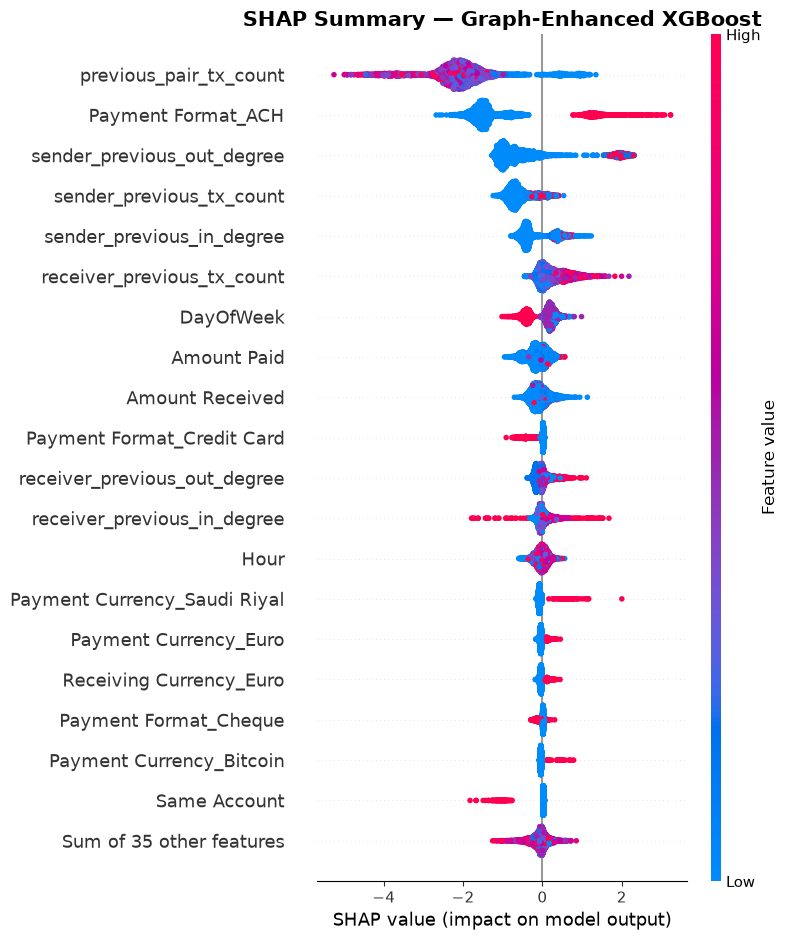

In [16]:
import shap

# Select a reproducible validation sample
X_shap = X_val.sample(
    n=5000,
    random_state=42
)

# Initialize the SHAP TreeExplainer
explainer = shap.TreeExplainer(best_graph_model)

# Calculate SHAP values
shap_values = explainer(X_shap)

# Display the SHAP summary plot
shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary — Graph-Enhanced XGBoost",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [17]:
# Calculate mean absolute SHAP values
shap_importance_df = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean Absolute SHAP": np.abs(shap_values.values).mean(axis=0)
})

# Identify feature groups
shap_importance_df["Feature Type"] = np.where(
    shap_importance_df["Feature"].isin(graph_features),
    "Graph",
    "Transaction"
)

# Rank features by SHAP importance
shap_importance_df = shap_importance_df.sort_values(
    "Mean Absolute SHAP", ascending=False
).reset_index(drop=True)

shap_importance_df.index += 1

# Display the top 20 features
display(shap_importance_df.head(20).round(4))

# Aggregate importance by feature group
group_importance = shap_importance_df.groupby(
    "Feature Type"
)["Mean Absolute SHAP"].sum()

group_share = group_importance / group_importance.sum() * 100

# Display group-level importance
display(pd.DataFrame({
    "Total Mean Absolute SHAP": group_importance,
    "Importance Share (%)": group_share
}).round(4))

,Feature,Mean Absolute SHAP,Feature Type
1,previous_pair_tx_count,2.1026,Graph
2,Payment Format_ACH,1.4594,Transaction
3,sender_previous_out_degree,0.8695,Graph
4,sender_previous_tx_count,0.6091,Graph
5,sender_previous_in_degree,0.4215,Graph
6,receiver_previous_tx_count,0.3064,Graph
7,DayOfWeek,0.2833,Transaction
8,Amount Paid,0.2060,Transaction
9,Amount Received,0.1737,Transaction
10,Payment Format_Credit Card,0.1381,Transaction


,Total Mean Absolute SHAP,Importance Share (%)
Feature Type,,
Graph,4.5615,59.717201
Transaction,3.0770,40.282799


In [18]:
# Identify traditional transaction features
transaction_features = [
    col for col in X_train.columns
    if col not in graph_features
]

# Define historical graph feature groups
sender_features = [
    "sender_previous_tx_count",
    "sender_previous_in_degree",
    "sender_previous_out_degree"
]

receiver_features = [
    "receiver_previous_tx_count",
    "receiver_previous_in_degree",
    "receiver_previous_out_degree"
]

pair_features = [
    "previous_pair_tx_count"
]

# Define ablation experiments
ablation_configs = {
    "Transaction Only": transaction_features,

    "Graph Only": graph_features,

    "Transaction + Sender":
        transaction_features + sender_features,

    "Transaction + Receiver":
        transaction_features + receiver_features,

    "Transaction + Pair":
        transaction_features + pair_features,

    "Full Without Pair":
        transaction_features
        + sender_features
        + receiver_features,

    "Full Graph XGBoost": X_train.columns.tolist()
}

# Validate the feature subsets
for name, features in ablation_configs.items():
    assert all(col in X_train.columns for col in features)
    assert len(features) == len(set(features))

# Display the experimental configurations
ablation_summary = pd.DataFrame([
    {
        "Experiment": name,
        "Transaction Features": sum(
            col in transaction_features for col in features
        ),
        "Graph Features": sum(
            col in graph_features for col in features
        ),
        "Total Features": len(features)
    }
    for name, features in ablation_configs.items()
])

display(ablation_summary)

,Experiment,Transaction Features,Graph Features,Total Features
0,Transaction Only,47,0,47
1,Graph Only,0,7,7
2,Transaction + Sender,47,3,50
3,Transaction + Receiver,47,3,50
4,Transaction + Pair,47,1,48
5,Full Without Pair,47,6,53
6,Full Graph XGBoost,47,7,54


In [19]:
# Retrieve the selected model configuration
ablation_params = best_graph_model.get_params()

ablation_results = []

# Train and evaluate each feature subset
for name, features in ablation_configs.items():

    started = perf_counter()

    # Reuse the existing full graph model
    if name == "Full Graph XGBoost":
        model = best_graph_model

    else:
        model = XGBClassifier(**ablation_params)

        model.fit(
            X_train[features],
            y_train,
            eval_set=[(X_val[features], y_val)],
            verbose=False
        )

    # Calculate validation predictions
    val_proba = model.predict_proba(
        X_val[features]
    )[:, 1]

    # Evaluate Average Precision
    val_ap = average_precision_score(y_val, val_proba)

    elapsed = perf_counter() - started

    # Store experiment results
    ablation_results.append({
        "Experiment": name,
        "Features": len(features),
        "Validation AP": val_ap,
        "Best Trees": model.best_iteration + 1,
        "Runtime (s)": elapsed
    })

    print(
        f"{name:25s} | "
        f"AP: {val_ap:.4%} | "
        f"Trees: {model.best_iteration + 1} | "
        f"Time: {elapsed:.1f}s"
    )

# Create the final results table
ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.sort_values(
        "Validation AP", ascending=False
    ).reset_index(drop=True)
)

Transaction Only          | AP: 6.6664% | Trees: 72 | Time: 25.1s
Graph Only                | AP: 21.4817% | Trees: 542 | Time: 110.5s
Transaction + Sender      | AP: 19.7117% | Trees: 317 | Time: 88.3s
Transaction + Receiver    | AP: 18.2677% | Trees: 348 | Time: 89.8s
Transaction + Pair        | AP: 24.1441% | Trees: 232 | Time: 57.2s
Full Without Pair         | AP: 30.8854% | Trees: 590 | Time: 144.9s
Full Graph XGBoost        | AP: 45.4112% | Trees: 520 | Time: 1.1s


,Experiment,Features,Validation AP,Best Trees,Runtime (s)
0,Full Graph XGBoost,54,0.454112,520,1.098829
1,Full Without Pair,53,0.308854,590,144.942212
2,Transaction + Pair,48,0.241441,232,57.212152
3,Graph Only,7,0.214817,542,110.471298
4,Transaction + Sender,50,0.197117,317,88.319155
5,Transaction + Receiver,50,0.182677,348,89.786045
6,Transaction Only,47,0.066664,72,25.106803


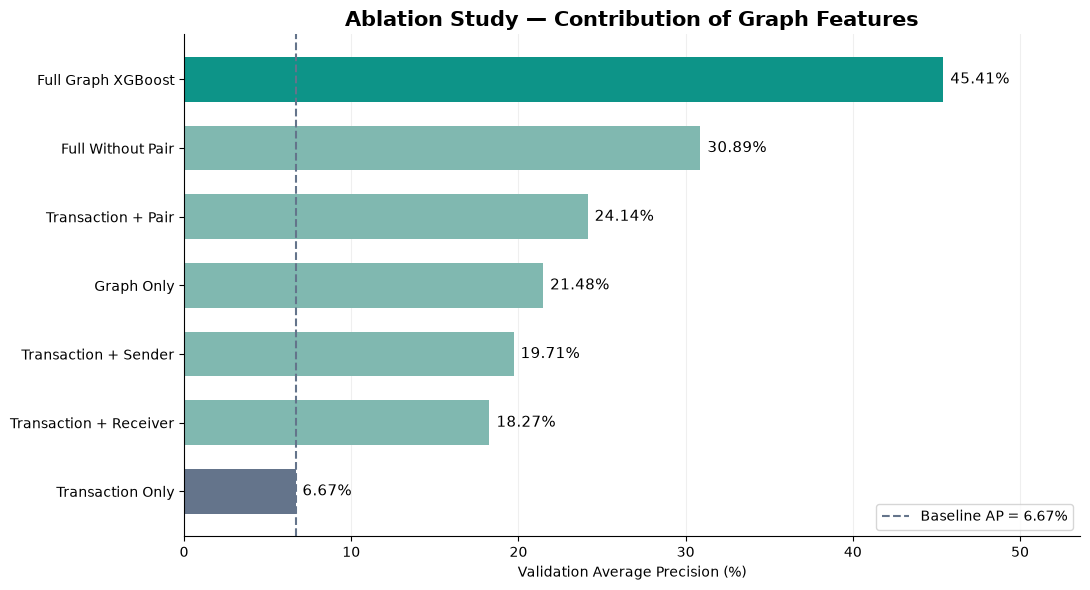

In [20]:
# Sort experiments by validation performance
plot_df = ablation_df.sort_values(
    "Validation AP", ascending=True
).copy()

# Convert Average Precision to percentages
plot_df["AP (%)"] = plot_df["Validation AP"] * 100

# Assign colors to experimental configurations
colors = [
    "#0D9488" if name == "Full Graph XGBoost"
    else "#64748B" if name == "Transaction Only"
    else "#80B8B0"
    for name in plot_df["Experiment"]
]

# Create the ablation comparison chart
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_df["Experiment"],
    plot_df["AP (%)"],
    color=colors,
    height=0.65
)

# Add performance labels
ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5,
    fontsize=11
)

# Add the baseline reference
baseline_ap = ablation_df.loc[
    ablation_df["Experiment"] == "Transaction Only",
    "Validation AP"
].iloc[0] * 100

ax.axvline(
    baseline_ap,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline AP = {baseline_ap:.2f}%"
)

# Format the chart
ax.set_title(
    "Ablation Study — Contribution of Graph Features",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Validation Average Precision (%)")
ax.set_xlim(0, plot_df["AP (%)"].max() * 1.18)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [21]:
# Generate test predictions using the selected model
graph_test_proba = best_graph_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected on the validation dataset
graph_test_pred = (
    graph_test_proba >= best_graph_threshold
).astype(int)

# Calculate test performance metrics
graph_test_ap = average_precision_score(
    y_test, graph_test_proba
)

graph_test_precision = precision_score(
    y_test, graph_test_pred, zero_division=0
)

graph_test_recall = recall_score(
    y_test, graph_test_pred
)

graph_test_f1 = f1_score(
    y_test, graph_test_pred
)

# Calculate confusion matrix statistics
tn, fp, fn, tp = confusion_matrix(
    y_test, graph_test_pred, labels=[0, 1]
).ravel()

# Display final test results
print("Graph XGBoost — Final Test Results")
print("-" * 45)

print(f"Threshold:         {best_graph_threshold:.6f}")
print(f"Average Precision: {graph_test_ap:.4%}")
print(f"Precision:         {graph_test_precision:.4%}")
print(f"Recall:            {graph_test_recall:.4%}")
print(f"F1-score:          {graph_test_f1:.4%}")

print("\nConfusion Matrix Statistics")
print(f"True Positives:    {tp:,}")
print(f"False Positives:   {fp:,}")
print(f"False Negatives:   {fn:,}")
print(f"True Negatives:    {tn:,}")
print(f"Total Alerts:      {tp + fp:,}")

Graph XGBoost — Final Test Results
---------------------------------------------
Threshold:         0.218607
Average Precision: 56.5791%
Precision:         70.9651%
Recall:            47.4416%
F1-score:          56.8667%

Confusion Matrix Statistics
True Positives:    853
False Positives:   349
False Negatives:   945
True Negatives:    1,013,735
Total Alerts:      1,202


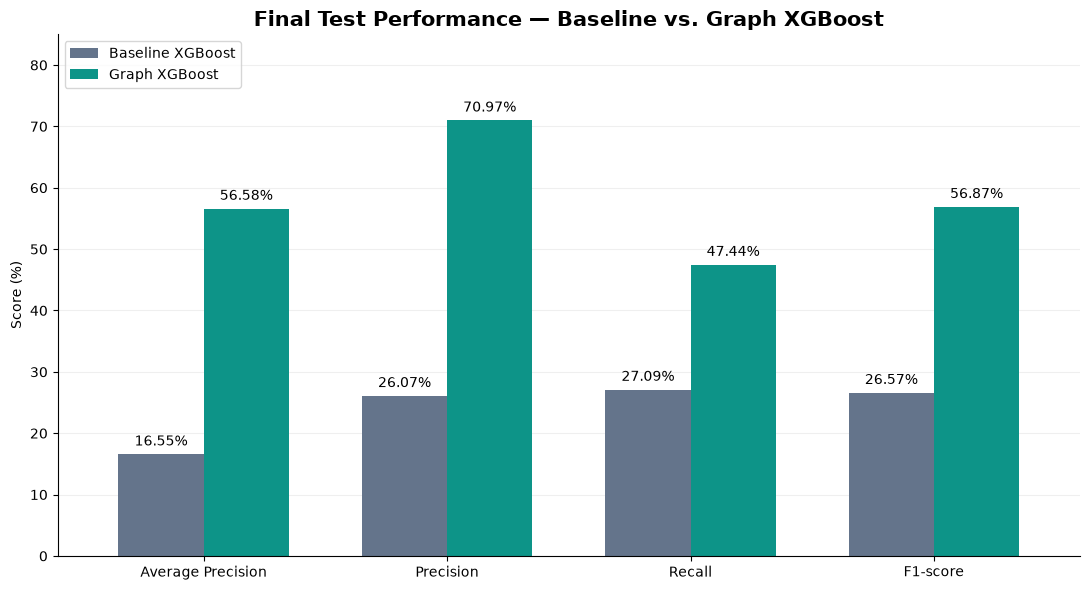

,Metric,Baseline XGBoost,Graph XGBoost
0,Average Precision,0.165498,0.565791
1,Precision,0.260700,0.709651
2,Recall,0.270900,0.474416
3,F1-score,0.265700,0.568667


In [22]:
# Create the final test performance comparison
test_comparison = pd.DataFrame({
    "Metric": [
        "Average Precision",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Baseline XGBoost": [
        0.1654976,
        0.2607,
        0.2709,
        0.2657
    ],
    "Graph XGBoost": [
        graph_test_ap,
        graph_test_precision,
        graph_test_recall,
        graph_test_f1
    ]
})

# Convert metrics to percentages
plot_df = test_comparison.set_index("Metric") * 100

# Create the comparison chart
fig, ax = plt.subplots(figsize=(11, 6))

plot_df.plot(
    kind="bar",
    ax=ax,
    color=["#64748B", "#0D9488"],
    width=0.7,
    rot=0
)

# Add performance labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4,
        fontsize=10
    )

# Format the chart
ax.set_title(
    "Final Test Performance — Baseline vs. Graph XGBoost",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Score (%)")
ax.set_xlabel("")
ax.set_ylim(0, 85)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper left")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

display(test_comparison.round(6))

In [ ]:
from pathlib import Path

# Create the model output directory
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define the model output path
MODEL_PATH = MODEL_DIR / "graph_xgboost.json"

# Save the selected graph-enhanced XGBoost model
best_graph_model.save_model(str(MODEL_PATH))

# Verify the exported model file
print("Model saved:", MODEL_PATH.exists())
print("File:", MODEL_PATH.resolve())
print(f"File size (MB): {MODEL_PATH.stat().st_size / 1024**2:.2f}")

Model saved: True
File: C:\Users\gokce\Desktop\CGML\models\graph_xgboost.json
File size (MB): 4.23


In [24]:
import json
import xgboost as xgb

# Define model metadata
metadata = {
    "model_name": "Graph-Enhanced XGBoost",
    "model_file": MODEL_PATH.name,
    "target": "Is Laundering",
    "threshold": float(best_graph_threshold),
    "feature_names": X_train.columns.tolist(),
    "transaction_features": transaction_features,
    "graph_features": graph_features,
    "total_features": X_train.shape[1],
    "best_iteration": int(best_graph_model.best_iteration),
    "best_trees": int(best_graph_model.best_iteration + 1),
    "hyperparameters": best_graph_model.get_params(),
    "xgboost_version": xgb.__version__,
    "pandas_version": pd.__version__
}

# Save metadata as a JSON file
METADATA_PATH = MODEL_DIR / "graph_xgboost_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

# Verify the metadata file
print("Metadata saved:", METADATA_PATH.exists())
print("File:", METADATA_PATH.resolve())
print("Total features:", metadata["total_features"])
print("Threshold:", metadata["threshold"])
print("Best trees:", metadata["best_trees"])

Metadata saved: True
File: C:\Users\gokce\Desktop\CGML\models\graph_xgboost_metadata.json
Total features: 54
Threshold: 0.21860717236995697
Best trees: 520


In [25]:
# Create the results output directory
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Define experimental results
results_to_export = {
    "graph_test_comparison.csv": test_comparison,
    "graph_ablation_results.csv": ablation_df,
    "graph_gain_importance.csv": importance_df,
    "graph_shap_importance.csv": shap_importance_df
}

# Export experimental results
for filename, results in results_to_export.items():
    output_path = RESULTS_DIR / filename
    results.to_csv(output_path, index=False)

    print(f"{filename}: Saved = {output_path.exists()}")

print("\nResults directory:", RESULTS_DIR.resolve())

graph_test_comparison.csv: Saved = True
graph_ablation_results.csv: Saved = True
graph_gain_importance.csv: Saved = True
graph_shap_importance.csv: Saved = True

Results directory: C:\Users\gokce\Desktop\CGML\results


In [26]:
import numpy as np

# Reload the saved model
loaded_model = XGBClassifier()
loaded_model.load_model(str(MODEL_PATH))

# Reload model metadata
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    loaded_metadata = json.load(f)

# Verify feature order
assert loaded_metadata["feature_names"] == X_test.columns.tolist()

# Generate predictions using the restored model
loaded_proba = loaded_model.predict_proba(X_test)[:, 1]

# Apply the saved classification threshold
loaded_pred = (
    loaded_proba >= loaded_metadata["threshold"]
).astype(int)

# Compare original and restored predictions
probabilities_match = np.allclose(
    graph_test_proba, loaded_proba, rtol=0, atol=1e-7
)

predictions_match = np.array_equal(
    graph_test_pred, loaded_pred
)

# Display verification results
print("Model loaded successfully.")
print("Feature order: PASSED")
print("Probabilities match:", probabilities_match)
print("Predictions match:", predictions_match)

print(
    "Maximum probability difference:",
    np.max(np.abs(graph_test_proba - loaded_proba))
)

assert probabilities_match
assert predictions_match

print("\nModel verification: PASSED")

Model loaded successfully.
Feature order: PASSED
Probabilities match: True
Predictions match: True
Maximum probability difference: 0.0

Model verification: PASSED
